In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hasanyiitakbulut/ai-and-human-text-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'ai-and-human-text-dataset' dataset.
Path to dataset files: /kaggle/input/ai-and-human-text-dataset


### 1. Downloading the Dataset
This cell uses the `kagglehub` library to download the latest version of the "AI and Human Text Dataset" from Kaggle and prints the local directory path where the downloaded dataset is stored.

In [2]:
import pandas as pd
import os

pat1 = os.path.join(path, "data_for_preprocessing.csv")

df = pd.read_csv(pat1)
df

,Unnamed: 0,Text,Author
0,0,This study investigates the chemical compositi...,AI
1,1,This study explores the cultural history of oi...,AI
2,2,Isolation of human peripheral blood mononucle...,Human
3,3,Dynamic Bayesian Networks (DBNs) are probabil...,Human
4,4,"Within volleyball, performance analysis is em...",Human
...,...,...,...
6064,6064,Computational models serve as useful compleme...,Human
6065,6065,During transport and storage of drinking wate...,Human
6066,6066,The parameter values of neural networks will ...,Human
6067,6067,Crumb Rubber Modified Asphalt (CRMA) offers a...,Human


### 2. Loading the Data
Here, we use `pandas` to read the CSV file (`data_for_preprocessing.csv`) from the downloaded path into a DataFrame (`df`) and display the first and last few rows of the loaded dataset.

In [36]:
df["Text"][2]

'isolation of human peripheral blood mononuclear cells pbmcs from blood typically involves a density gradient medium during density centrifugation the problem of increasing red blood cell rbc and granulocyte gra contamination during pbmc isolation as the elapsed time after blood collection increases remains unresolved as a countermeasure against rbc contamination hemolysis treatment is available however these extra steps are laborious timeconsuming and could introduce artifacts to overcome this challenge we developed a novel isolation device flowmagic which features a proprietary twolayer insert structure designed to prevent rbc and gra contamination during pbmc isolation from blood the efficacy of this method was evaluated by isolating pbmcs from donors and analyzing immune cell populations by flow cytometry compared to sepmate median q interquartile ranges iqr p and lymphoprep methods q iqr p flowmagic achieved significantly greater reduction in rbc contamination to below detectable 

### 3. Reviewing Raw Sample Text
This cell displays the very first text sample (`index 0`) from the dataset to understand the structure and style of the text before any preprocessing.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6069 entries, 0 to 6068
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  6069 non-null   int64 
 1   Text        6069 non-null   object
 2   Author      6069 non-null   object
dtypes: int64(1), object(2)
memory usage: 142.4+ KB


### 4. Inspecting Dataset Structure
This cell calls `.info()` on the DataFrame to inspect metadata such as column names, data types, the count of non-null values, and memory usage.

In [4]:
df.isnull().sum()

,0
Unnamed: 0,0
Text,0
Author,0


### 5. Checking for Missing Values
We calculate the sum of missing (`NaN`) values for each column to confirm if any data imputation or removal of empty entries is necessary.

In [5]:
df.duplicated().sum()

np.int64(0)

### 6. Checking for Duplicate Rows
This cell checks the dataset for duplicated rows to ensure data uniqueness and avoid leakage during model training.

In [6]:
df["Author"].value_counts()

,count
Author,
AI,3069
Human,3000


### 7. Class Distribution (Value Counts)
We count the number of samples belonging to each target class (`AI` vs. `Human`) in the `Author` column to see if the dataset is balanced.

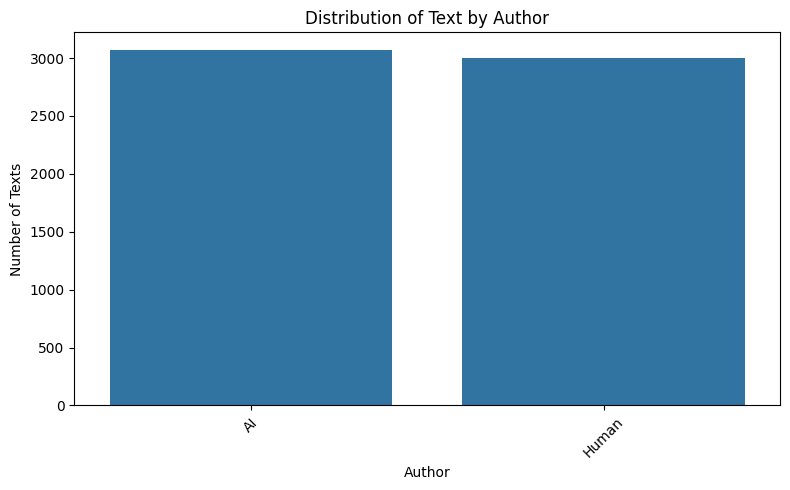

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Author")

plt.title("Distribution of Text by Author")
plt.xlabel("Author")
plt.ylabel("Number of Texts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 8. Visualizing Class Counts
Using `seaborn` and `matplotlib`, this cell creates a bar chart (countplot) showing the frequency distribution of the two classes (`AI` and `Human`).

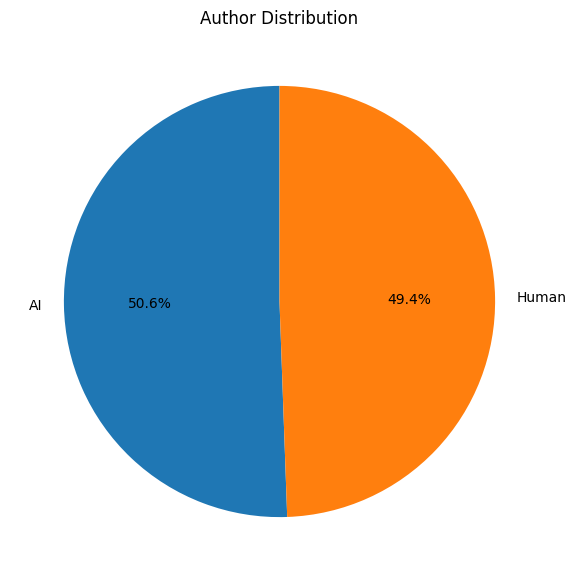

In [8]:
author_counts = df["Author"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    author_counts.values,
    labels=author_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Author Distribution")
plt.show()

### 9. Class Distribution Percentage
This cell displays a pie chart showcasing the exact percentage split between AI-generated and Human-authored texts.

In [9]:
import pandas as pd
from sklearn.utils import resample

# Original class distribution
print("Before balancing:")
print(df["Author"].value_counts())

# Har class ke records alag karo
classes = df["Author"].unique()

if len(classes) != 2:
    raise ValueError("Is code ke liye Author column mein exactly 2 classes honi chahiye.")

class_1 = df[df["Author"] == classes[0]]
class_2 = df[df["Author"] == classes[1]]

# Total dataset size preserve karte hue 60:40 ratio
total = len(df)
n1 = round(total * 0.60)
n2 = total - n1

# Dono classes ko required size mein sample karo
if len(class_1) >= n1 and len(class_2) >= n2:
    df2 = pd.concat([
        class_1.sample(n=n1, random_state=42),
        class_2.sample(n=n2, random_state=42)
    ])
elif len(class_1) >= n1:
    df2 = pd.concat([
        class_1.sample(n=n1, random_state=42),
        class_2.sample(n=n2, replace=True, random_state=42)
    ])
else:
    df2 = pd.concat([
        class_1.sample(n=n1, replace=True, random_state=42),
        class_2.sample(n=n2, random_state=42)
    ])

# Shuffle dataset
df2 = df2.sample(frac=1, random_state=42).reset_index(drop=True)

# Result check karo
print("\nAfter balancing:")
print(df2["Author"].value_counts())
print("\nPercentage:")
print((df2["Author"].value_counts(normalize=True) * 100).round(2))

print("\nNew dataset shape:", df2.shape)

Before balancing:
Author
AI       3069
Human    3000
Name: count, dtype: int64

After balancing:
Author
AI       3641
Human    2428
Name: count, dtype: int64

Percentage:
Author
AI       59.99
Human    40.01
Name: proportion, dtype: float64

New dataset shape: (6069, 3)


### 10. Dataset Re-balancing (60:40 Split)
This script separates the classes and resamples them (using upsampling/downsampling) to enforce a specific 60% AI to 40% Human distribution ratio.

In [10]:
df.drop(columns=["Unnamed: 0"], inplace=True)


### 11. Dropping Unnecessary Columns
This step drops the index column `Unnamed: 0` in-place as it acts as an arbitrary row counter and is not needed for model training.

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6069 entries, 0 to 6068
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Text    6069 non-null   object
 1   Author  6069 non-null   object
dtypes: object(2)
memory usage: 95.0+ KB


### 12. Final Pre-Cleaning Check
This cell runs another `.info()` check to verify that `Unnamed: 0` was successfully dropped and only the clean columns remain.

In [12]:
import re

# Missing values check karo
print(df[["Text", "Author"]].isnull().sum())

# Missing values remove karo
df = df.dropna(subset=["Text", "Author"]).copy()

# Text cleaning
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)  # URLs remove
    text = re.sub(r'<.*?>', '', text)           # HTML tags remove
    text = re.sub(r'[^a-zA-Z\s]', '', text)     # Special characters/numbers remove
    text = re.sub(r'\s+', ' ', text).strip()    # Extra spaces remove
    return text

df["Text"] = df["Text"].apply(clean_text)

# Result check
print(df[["Text", "Author"]].head(10))
print("Dataset Shape:", df.shape)

Text      0
Author    0
dtype: int64
                                                Text Author
0  this study investigates the chemical compositi...     AI
1  this study explores the cultural history of oi...     AI
2  isolation of human peripheral blood mononuclea...  Human
3  dynamic bayesian networks dbns are probabilist...  Human
4  within volleyball performance analysis is empl...  Human
5  intent is an evidencebased smoking prevention ...  Human
6  traditional opera is continuously involved in ...  Human
7  this research analyzes how mughal miniature pa...     AI
8  this study examines the dialectology of the bl...     AI
9  understanding dream formation is scientificall...     AI
Dataset Shape: (6069, 2)


### 13. Text Cleaning (Regular Expressions)
This cell cleans the text by converting it to lowercase and using regular expressions (`re`) to strip out URLs, HTML tags, special characters, and extra white spaces.

In [14]:
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

# Required NLTK resources
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

# English stopwords
stop_words = set(stopwords.words("english"))

# Tokenization
df["Tokens"] = df["Text"].apply(word_tokenize)

# Stopword removal
df["Tokens"] = df["Tokens"].apply(
    lambda words: [word for word in words if word not in stop_words]
)

# Check result
print(df[["Text", "Tokens", "Author"]].head(10))

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


                                                Text  \
0  this study investigates the chemical compositi...   
1  this study explores the cultural history of oi...   
2  isolation of human peripheral blood mononuclea...   
3  dynamic bayesian networks dbns are probabilist...   
4  within volleyball performance analysis is empl...   
5  intent is an evidencebased smoking prevention ...   
6  traditional opera is continuously involved in ...   
7  this research analyzes how mughal miniature pa...   
8  this study examines the dialectology of the bl...   
9  understanding dream formation is scientificall...   

                                              Tokens Author  
0  [study, investigates, chemical, composition, t...     AI  
1  [study, explores, cultural, history, oil, wres...     AI  
2  [isolation, human, peripheral, blood, mononucl...  Human  
3  [dynamic, bayesian, networks, dbns, probabilis...  Human  
4  [within, volleyball, performance, analysis, em...  Human  
5  [intent,

### 14. Tokenization and Stopword Removal
This cell downloads resources from `nltk` to tokenize the text into individual words, and then filters out standard English stop words (like 'the', 'is', 'and') that do not carry semantic classification weight.

In [15]:
import nltk
from nltk.stem import WordNetLemmatizer

# Required resources
nltk.download("wordnet")
nltk.download("omw-1.4")

# Create lemmatizer
lemmatizer = WordNetLemmatizer()

# Lemmatization
df["Tokens"] = df["Tokens"].apply(
    lambda words: [
        lemmatizer.lemmatize(word) for word in words
    ]
)

# Check output
print(df[["Tokens", "Author"]].head(10))

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


                                              Tokens Author
0  [study, investigates, chemical, composition, t...     AI
1  [study, explores, cultural, history, oil, wres...     AI
2  [isolation, human, peripheral, blood, mononucl...  Human
3  [dynamic, bayesian, network, dbns, probabilist...  Human
4  [within, volleyball, performance, analysis, em...  Human
5  [intent, evidencebased, smoking, prevention, p...  Human
6  [traditional, opera, continuously, involved, c...  Human
7  [research, analyzes, mughal, miniature, painti...     AI
8  [study, examines, dialectology, black, sea, re...     AI
9  [understanding, dream, formation, scientifical...     AI


### 15. Lemmatization
This cell lemmatizes each token using WordNet, reducing words to their root/base form (e.g., "springs" to "spring") so similar variations map to the same token.

In [16]:
df["Processed_Text"] = df["Tokens"].apply(
    lambda words: " ".join(words)
)

print(df[["Processed_Text", "Author"]].head(10))

                                      Processed_Text Author
0  study investigates chemical composition therma...     AI
1  study explores cultural history oil wrestling ...     AI
2  isolation human peripheral blood mononuclear c...  Human
3  dynamic bayesian network dbns probabilistic mo...  Human
4  within volleyball performance analysis employe...  Human
5  intent evidencebased smoking prevention progra...  Human
6  traditional opera continuously involved constr...  Human
7  research analyzes mughal miniature painting sy...     AI
8  study examines dialectology black sea region f...     AI
9  understanding dream formation scientifically d...     AI


### 16. Rejoining Tokens into Clean Text
This cell converts the processed list of tokens back into unified space-separated text strings, saved under the new column `Processed_Text`.

In [17]:
from sklearn.preprocessing import LabelEncoder

# Label Encoder
le = LabelEncoder()

df["Author_Encoded"] = le.fit_transform(df["Author"])

# Check encoding
print("Author Mapping:")
for author, encoded in zip(le.classes_, le.transform(le.classes_)):
    print(author, "=", encoded)

print(df[["Processed_Text", "Author", "Author_Encoded"]].head(10))

Author Mapping:
AI = 0
Human = 1
                                      Processed_Text Author  Author_Encoded
0  study investigates chemical composition therma...     AI               0
1  study explores cultural history oil wrestling ...     AI               0
2  isolation human peripheral blood mononuclear c...  Human               1
3  dynamic bayesian network dbns probabilistic mo...  Human               1
4  within volleyball performance analysis employe...  Human               1
5  intent evidencebased smoking prevention progra...  Human               1
6  traditional opera continuously involved constr...  Human               1
7  research analyzes mughal miniature painting sy...     AI               0
8  study examines dialectology black sea region f...     AI               0
9  understanding dream formation scientifically d...     AI               0


### 17. Encoding Categorical Targets
Using `LabelEncoder`, this cell maps our categorical target column `Author` ('AI'/'Human') into numeric binary form (0 for AI, 1 for Human).

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF
tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(df["Processed_Text"])

# Target column
y = df["Author_Encoded"]

print("TF-IDF Shape:", X.shape)
print("Target Shape:", y.shape)

TF-IDF Shape: (6069, 5000)
Target Shape: (6069,)


### 18. Feature Extraction (TF-IDF Vectorization)
This step uses `TfidfVectorizer` to transform our text data into numerical sparse matrices (`X`) containing TF-IDF weights for up to 5,000 top vocabulary terms.

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)



### 19. Train-Test Split
This cell splits our data features (`X`) and target labels (`y`) into 80% training data and 20% testing data, ensuring class distribution remains proportional using `stratify`.

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Model
lr_model = LogisticRegression(max_iter=1000)

# Training
lr_model.fit(X_train, y_train)

# Prediction
y_pred = lr_model.predict(X_test)

# Accuracy
print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

# Classification Report
print(classification_report(y_test, y_pred))



Logistic Regression Accuracy: 97.94 %
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       614
           1       0.99      0.97      0.98       600

    accuracy                           0.98      1214
   macro avg       0.98      0.98      0.98      1214
weighted avg       0.98      0.98      0.98      1214



### 20. Model Training and Evaluation
Here, a Logistic Regression model is trained on the training subset, makes predictions on the test set, and outputs the overall classification performance metrics (accuracy, precision, recall, and f1-score).

In [26]:
import joblib

# Save all files
joblib.dump(lr_model, "logistic_regression_model.joblib")
joblib.dump(le, "label_encoder.joblib")
joblib.dump(tfidf, "tfidf_vectorizer.joblib")

print("Model, LabelEncoder and TF-IDF saved successfully!")

Model, LabelEncoder and TF-IDF saved successfully!


### 21. Exporting Pipeline Artifacts
This cell uses `joblib` to serialize and save the trained Logistic Regression model, the TF-IDF vectorizer, and the Label Encoder into file artifacts for later inference.

In [27]:
import joblib

# Load all files
loaded_model = joblib.load("logistic_regression_model.joblib")
loaded_encoder = joblib.load("label_encoder.joblib")
loaded_tfidf = joblib.load("tfidf_vectorizer.joblib")

print("All files loaded successfully!")

All files loaded successfully!


### 22. Verification of Saved Pipeline Artifacts
This cell tests the reloading process of the exported joblib files to verify they can be successfully loaded back into memory without issues.

In [34]:
# Input Text
text = ["this study investigates the chemical composition of thermal springs in afyonkarahisar assessing their potential for health tourism"]

# TF-IDF Transformation
text_vector = loaded_tfidf.transform(text)

# Model Prediction
prediction = loaded_model.predict(text_vector)

# Decode Author Name
author = loaded_encoder.inverse_transform(prediction)

print("Predicted Author:", author[0])

Predicted Author: AI


### 23. Interactive Inference Pipeline Demo
This final cell demonstrates the complete inference pipeline on a raw text string by transforming it with our loaded TF-IDF vectorizer, passing it to our Logistic Regression classifier, and reversing the numeric output to display the human-readable predicted Author.